<a href="https://colab.research.google.com/github/OluwatifeAkinsola/RAG-Chatbot/blob/main/CUSTOMER_CHURN_PREDICTION_%26_RETENTION_DASHBOARD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install opendatasets library for downloading datasets from Kaggle
!pip install opendatasets --upgrade --quiet

import opendatasets as od

# Download the Telco Customer Churn dataset from Kaggle
od.download('https://www.kaggle.com/datasets/blastchar/telco-customer-churn')

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: sirdavidakinsola
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn


100%|██████████| 172k/172k [00:00<00:00, 74.6MB/s]

In [ ]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

# Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# Interpretability
import shap

# Set style
plt.style.use('ggplot')
sns.set_palette("Set2")

In [ ]:
# Load dataset
df = pd.read_csv('telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Quick look
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution (Churn):")
print(df['Churn'].value_counts(normalize=True))

Dataset shape: (7043, 21)

First 5 rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport Streami

In [ ]:
# TotalCharges is object type? Convert to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check missing values after conversion
print(f"Missing values in TotalCharges: {df['TotalCharges'].isnull().sum()}")

# Drop rows with missing TotalCharges (only 11 rows)
df = df.dropna(subset=['TotalCharges'])

# Drop customerID – not useful for prediction
df = df.drop('customerID', axis=1)

print(f"Final dataset shape: {df.shape}")

Missing values in TotalCharges: 11
Final dataset shape: (7032, 20)


In [ ]:
# Convert binary categorical columns to 0/1
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']

for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0, 'Female': 0, 'Male': 1})

# One-hot encode multiple-category columns
categorical_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
                    'Contract', 'PaymentMethod']

df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Create tenure groups (bucketing)
df['tenure_group'] = pd.cut(df['tenure'], bins=[0, 12, 24, 48, 60, 72], labels=['0-1yr', '1-2yr', '2-4yr', '4-5yr', '5-6yr'])
df = pd.get_dummies(df, columns=['tenure_group'], drop_first=True)

print(f"Features after engineering: {df.shape[1]}")

Features after engineering: 35


In [ ]:
# Target column
y = df['Churn'].values

# Features (everything except target)
X = df.drop('Churn', axis=1)

# Split into train (80%) and test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")

Train shape: (5625, 34)
Test shape: (1407, 34)


In [ ]:
# Scale numeric columns (important for logistic regression and interpretability)
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()

X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [ ]:
dt = DecisionTreeClassifier(max_depth=5, min_samples_split=50, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
dt_proba = dt.predict_proba(X_test)[:, 1]

print("=== DECISION TREE ===")
print(f"Accuracy: {accuracy_score(y_test, dt_pred):.4f}")
print(f"Precision: {precision_score(y_test, dt_pred):.4f}")
print(f"Recall: {recall_score(y_test, dt_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, dt_pred):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, dt_proba):.4f}")

=== DECISION TREE ===
Accuracy: 0.7783
Precision: 0.5807
Recall: 0.5963
F1 Score: 0.5884
AUC-ROC: 0.8195


In [ ]:
rf = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=50, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

print("\n=== RANDOM FOREST ===")
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision: {precision_score(y_test, rf_pred):.4f}")
print(f"Recall: {recall_score(y_test, rf_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, rf_pred):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, rf_proba):.4f}")


=== RANDOM FOREST ===
Accuracy: 0.7896
Precision: 0.6393
Recall: 0.4786
F1 Score: 0.5474
AUC-ROC: 0.8383


In [ ]:
rf = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=50, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

print("\n=== RANDOM FOREST ===")
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision: {precision_score(y_test, rf_pred):.4f}")
print(f"Recall: {recall_score(y_test, rf_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, rf_pred):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, rf_proba):.4f}")


=== RANDOM FOREST ===
Accuracy: 0.7896
Precision: 0.6393
Recall: 0.4786
F1 Score: 0.5474
AUC-ROC: 0.8383


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [00:00:08] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



=== XGBoost ===
Accuracy: 0.7733
Precision: 0.5775
Recall: 0.5481
F1 Score: 0.5624
AUC-ROC: 0.8184
           Model  Accuracy  Precision    Recall        F1   AUC-ROC
0  Decision Tree  0.778252   0.580729  0.596257  0.588391  0.819510
1  Random Forest  0.789623   0.639286  0.478610  0.547401  0.838314
2        XGBoost  0.773276   0.577465  0.548128  0.562414  0.818385


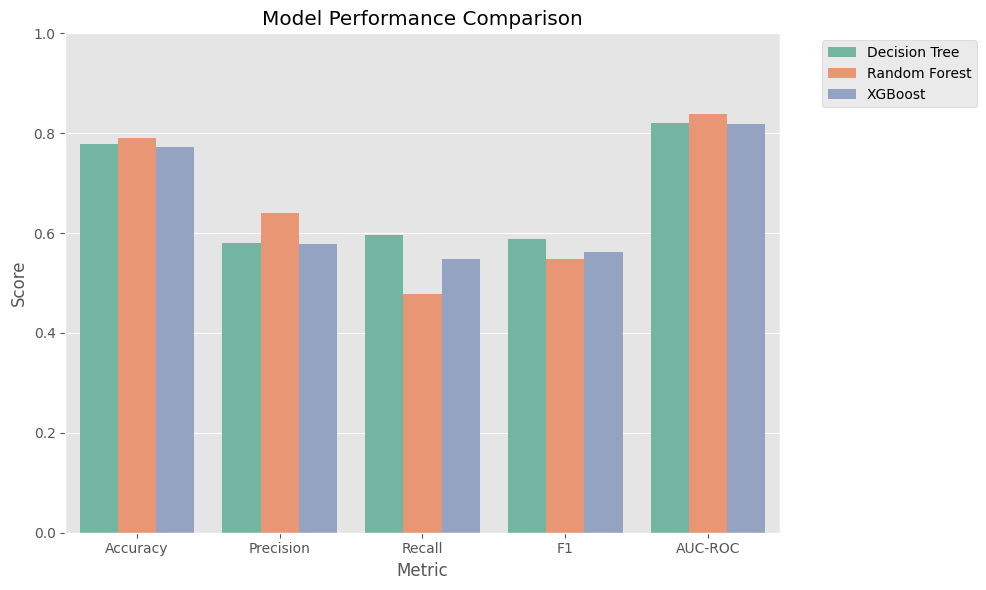

In [ ]:
# Train XGBoost model
xgb_model = xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

# Make predictions and get probabilities for XGBoost
xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

print("\n=== XGBoost ===")
print(f"Accuracy: {accuracy_score(y_test, xgb_pred):.4f}")
print(f"Precision: {precision_score(y_test, xgb_pred):.4f}")
print(f"Recall: {recall_score(y_test, xgb_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, xgb_pred):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, xgb_proba):.4f}")

# Create comparison DataFrame
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest', 'XGBoost'],
    'Accuracy': [accuracy_score(y_test, dt_pred), accuracy_score(y_test, rf_pred), accuracy_score(y_test, xgb_pred)],
    'Precision': [precision_score(y_test, dt_pred), precision_score(y_test, rf_pred), precision_score(y_test, xgb_pred)],
    'Recall': [recall_score(y_test, dt_pred), recall_score(y_test, rf_pred), recall_score(y_test, xgb_pred)],
    'F1': [f1_score(y_test, dt_pred), f1_score(y_test, rf_pred), f1_score(y_test, xgb_pred)],
    'AUC-ROC': [roc_auc_score(y_test, dt_proba), roc_auc_score(y_test, rf_proba), roc_auc_score(y_test, xgb_proba)]
})

print(results)

# Plot comparison
fig, ax = plt.subplots(figsize=(10, 6))
results_melted = results.melt(id_vars='Model', var_name='Metric', value_name='Score')
sns.barplot(data=results_melted, x='Metric', y='Score', hue='Model')
plt.title('Model Performance Comparison')
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

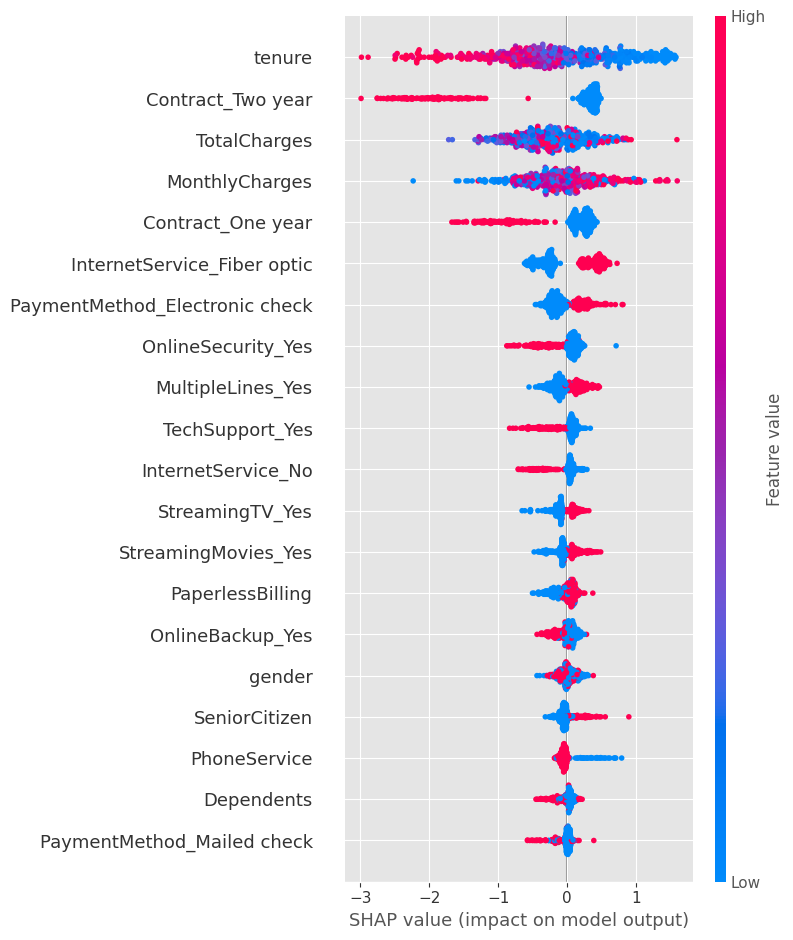

In [ ]:
# SHAP requires a small sample for speed
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test.sample(500, random_state=42))

# Summary plot
shap.summary_plot(shap_values, X_test.sample(500, random_state=42), feature_names=X.columns.tolist())

In [ ]:
# Grid search for better performance
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'n_estimators': [50, 100, 200],
    'subsample': [0.8, 1.0]
}

grid_search = GridSearchCV(xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss'),
                           param_grid, cv=5, scoring='roc_auc', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV AUC-ROC: {grid_search.best_score_:.4f}")

# Evaluate best model
best_xgb = grid_search.best_estimator_
best_pred = best_xgb.predict(X_test)
best_proba = best_xgb.predict_proba(X_test)[:, 1]
print(f"Test AUC-ROC with tuned model: {roc_auc_score(y_test, best_proba):.4f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best CV AUC-ROC: 0.8486
Test AUC-ROC with tuned model: 0.8394


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [00:02:13] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
